# 18장. 선형 분류기

| 항목 | 내용 |
|---|---|
| 예상 시간 | 4시간 |
| 선수 장 | 3장 (내적), 17장 |
| 이 장의 결과물 | 로지스틱 회귀 기본선, 클래스별 대표 단어 표, LinearSVC 비교 |
| 과제 연결 | 기본선: Logistic Regression 또는 Linear SVM 중 택1 |

**학습 목표**
- 선형 모델의 점수 $w \cdot x + b$를 TF-IDF 벡터로 직접 계산할 수 있다.
- 시그모이드와 소프트맥스로 점수가 확률이 되는 과정을 설명하고 `predict_proba`와 대조할 수 있다.
- 로지스틱 회귀와 선형 SVM의 차이를 직관적으로 설명할 수 있다.
- 규제 강도 `C`가 과적합과 어떤 관계인지 실험으로 보여 줄 수 있다.
- 고차원 희소 특성에 선형 모델이 잘 맞는 이유를 말할 수 있다.
- 학습된 계수로 클래스별 대표 단어를 뽑고 해석할 수 있다.

In [1]:
# ── 7장에서 만든 데이터 로딩 코드 (src/data.py로 옮길 내용) ──
import re
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.datasets import fetch_20newsgroups

PROJECT = Path.cwd().parent if Path.cwd().name == "studys" else Path.cwd()
RANDOM_STATE = 42
EN_CATEGORIES = ["comp.graphics", "comp.windows.x", "rec.sport.baseball", "rec.sport.hockey", "sci.space"]
YNAT_URL = ("https://raw.githubusercontent.com/KLUE-benchmark/KLUE/main/"
            "klue_benchmark/ynat-v1.1/ynat-v1.1_train.json")
YNAT_PATH = PROJECT / "data" / "raw" / "ynat-v1.1_train.json"

_EMAIL = re.compile(r"\S+@\S+\.\S+")
_URL = re.compile(r"(https?://|www\.)\S+")
_PHONE = re.compile(r"\b\d{2,4}[-.\s]\d{3,4}[-.\s]\d{4}\b")


def mask_pii(text: str) -> str:
    text = _EMAIL.sub(" <email> ", text)
    text = _URL.sub(" <url> ", text)
    return _PHONE.sub(" <phone> ", text)


def finalize(df: pd.DataFrame) -> pd.DataFrame:
    """개인정보 가리기 → 빈 문서 제거 → 레이블 충돌 중복·중복 제거 → 인덱스 재정렬."""
    df = df.assign(text=df["text"].map(mask_pii).str.strip())
    df = df[df["text"] != ""]
    norm = df["text"].str.split().str.join(" ")
    conflict = df.groupby(norm)["label"].transform("nunique") > 1
    df, norm = df[~conflict], norm[~conflict]
    return df[~norm.duplicated(keep="first")].reset_index(drop=True)


def load_english() -> pd.DataFrame:
    bunch = fetch_20newsgroups(subset="all", categories=EN_CATEGORIES,
                               remove=("headers", "footers", "quotes"),
                               shuffle=True, random_state=RANDOM_STATE)
    labels = [bunch.target_names[t] for t in bunch.target]
    return finalize(pd.DataFrame({"text": bunch.data, "label": labels}))


def load_korean(per_class: int = 1000) -> pd.DataFrame:
    if not YNAT_PATH.exists():
        YNAT_PATH.parent.mkdir(parents=True, exist_ok=True)
        urllib.request.urlretrieve(YNAT_URL, YNAT_PATH)
    raw = pd.read_json(YNAT_PATH).rename(columns={"title": "text"})[["guid", "text", "label"]]
    sampled = (raw.groupby("label", group_keys=False)
                  .sample(n=per_class, random_state=RANDOM_STATE)
                  .sample(frac=1.0, random_state=RANDOM_STATE))
    return finalize(sampled.reset_index(drop=True))

# ── 8~10장에서 만든 전처리 파이프라인 (src/preprocess.py로 옮길 내용) ──
from konlpy.tag import Okt
from nltk.corpus import stopwords

PLACEHOLDER = re.compile(r"<(?:email|url|phone)>")
EN_TOKEN = re.compile(r"[a-z]+(?:'[a-z]+)*")
KO_CLEAN = re.compile(r"[^0-9a-zA-Z가-힣一-鿿\s]")
HANJA_ONLY = re.compile(r"^[一-鿿]+$")
KO_KEEP_POS = {"Noun", "Verb", "Adjective", "Alpha"}
EN_STOP = frozenset(stopwords.words("english"))
DOMAIN_STOPWORDS_EN = frozenset({
    "would", "could", "might", "may", "also", "like", "get", "got", "go", "going", "know", "think",
    "see", "say", "make", "want", "look", "one", "well", "much", "many", "even", "way", "something",
    "anyone", "since", "still", "really", "right", "another", "cant",
})
STOPWORDS_KO = frozenset({
    "하다", "되다", "있다", "없다", "이다", "않다",
    "등", "것", "수", "중", "및", "때", "후", "내", "듯", "제", "개", "의", "로", "종합",
})
_okt = Okt()


def clean_en(text: str) -> str:
    text = PLACEHOLDER.sub(" ", text.lower()).replace("’", "'")
    return " ".join(EN_TOKEN.findall(text))


def clean_ko(text: str) -> str:
    return " ".join(KO_CLEAN.sub(" ", PLACEHOLDER.sub(" ", text)).split())


class EnglishPreprocessor:
    def __init__(self, use_domain_stopwords: bool = True, min_len: int = 2, max_len: int = 20):
        self.stopwords = EN_STOP | (DOMAIN_STOPWORDS_EN if use_domain_stopwords else frozenset())
        self.min_len, self.max_len = min_len, max_len

    def __call__(self, text: str) -> list[str]:
        tokens = []
        for tok in clean_en(text).split():
            if tok in self.stopwords:
                continue
            tok = tok.removesuffix("'s").replace("'", "")
            if self.min_len <= len(tok) <= self.max_len and tok not in self.stopwords:
                tokens.append(tok)
        return tokens


class KoreanPreprocessor:
    def __init__(self, tokenizer: str = "okt", use_stopwords: bool = True):
        if tokenizer not in ("okt", "whitespace"):
            raise ValueError(f"tokenizer는 'okt' 또는 'whitespace': {tokenizer}")
        self.tokenizer = tokenizer
        self.stopwords = STOPWORDS_KO if use_stopwords else frozenset()

    def tokenize(self, text: str) -> list[str]:
        if self.tokenizer == "whitespace":
            return clean_ko(text).lower().split()
        return [w.lower() for w, p in _okt.pos(clean_ko(text), norm=True, stem=True)
                if p in KO_KEEP_POS or (p == "Foreign" and HANJA_ONLY.match(w))]

    def __call__(self, text: str) -> list[str]:
        return [t for t in self.tokenize(text) if t not in self.stopwords and not t.isdigit()]

# ── 로드 + 전처리를 한 번에 (src/corpus.py로 옮길 내용) ──
MIN_TOKENS = {"en": 5, "ko": 2}   # 전처리 후 토큰이 이보다 적은 문서는 뺀다 (짧은 답글, 주제어 없는 제목)
MIN_DF = {"en": 3, "ko": 2}       # 어휘에 넣을 최소 문서 빈도 (11장)


def load_corpus(lang: str, tokenizer: str = "okt") -> pd.DataFrame:
    """열: text, label, tokens. lang은 "en" 또는 "ko"."""
    df = load_english() if lang == "en" else load_korean()
    prep = EnglishPreprocessor() if lang == "en" else KoreanPreprocessor(tokenizer)
    df["tokens"] = [prep(t) for t in df["text"]]
    df = df[df["tokens"].map(len) >= MIN_TOKENS[lang]].reset_index(drop=True)
    df.attrs["preprocessor"] = prep
    return df

# ── 13장에서 만든 NumPy TF-IDF (src/tfidf.py로 옮길 내용) ──
class NumpyTfidf:
    """TF(raw 또는 log) × smooth IDF, 문서마다 L2 정규화. sklearn TfidfVectorizer와 같은 정의."""

    def __init__(self, tf: str = "raw", smooth_idf: bool = True, norm: str | None = "l2",
                 min_df: int = 1, max_df: float = 1.0):
        if tf not in ("raw", "log"):
            raise ValueError(f"tf는 'raw' 또는 'log': {tf}")
        if norm not in ("l2", None):
            raise ValueError(f"norm은 'l2' 또는 None: {norm}")
        self.tf, self.smooth_idf, self.norm = tf, smooth_idf, norm
        self.min_df, self.max_df = min_df, max_df

    def fit(self, docs: list[list[str]]) -> "NumpyTfidf":
        n = len(docs)
        df: dict[str, int] = {}
        for doc in docs:
            for t in set(doc):
                df[t] = df.get(t, 0) + 1
        max_count = self.max_df * n if isinstance(self.max_df, float) else self.max_df
        terms = sorted(t for t, c in df.items() if self.min_df <= c <= max_count)
        self.vocabulary_ = {t: i for i, t in enumerate(terms)}
        self.terms_ = np.array(terms, dtype=object)
        self.n_docs_ = n
        self.df_ = np.array([df[t] for t in terms], dtype=np.float64)
        if self.smooth_idf:
            self.idf_ = np.log((1.0 + n) / (1.0 + self.df_)) + 1.0
        else:
            self.idf_ = np.log(n / self.df_) + 1.0
        return self

    def count_matrix(self, docs: list[list[str]]) -> np.ndarray:
        rows, cols = [], []
        for i, doc in enumerate(docs):
            for t in doc:
                j = self.vocabulary_.get(t)
                if j is not None:
                    rows.append(i)
                    cols.append(j)
        counts = np.zeros((len(docs), len(self.vocabulary_)), dtype=np.float64)
        np.add.at(counts, (np.asarray(rows, dtype=np.int64), np.asarray(cols, dtype=np.int64)), 1.0)
        return counts

    def transform(self, docs: list[list[str]]) -> np.ndarray:
        x = self.count_matrix(docs)
        if self.tf == "log":
            mask = x > 0
            x[mask] = 1.0 + np.log(x[mask])
        x *= self.idf_                                   # (n, V) * (V,) 브로드캐스팅
        if self.norm == "l2":
            norms = np.linalg.norm(x, axis=1, keepdims=True)
            x /= np.where(norms > 0, norms, 1.0)          # 빈 문서는 0 벡터로 둔다
        return x

    def fit_transform(self, docs: list[list[str]]) -> np.ndarray:
        return self.fit(docs).transform(docs)

# ── 17장에서 만든 분할·분류 코드 (src/classify.py로 옮길 내용) ──
from types import SimpleNamespace

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import train_test_split


def split(corpus: pd.DataFrame, seed: int = RANDOM_STATE) -> tuple[pd.DataFrame, pd.DataFrame]:
    train, test = train_test_split(corpus, test_size=0.2, stratify=corpus["label"], random_state=seed)
    return train.reset_index(drop=True), test.reset_index(drop=True)


def run_classification(corpus: pd.DataFrame, lang: str, seed: int = RANDOM_STATE, C: float = 1.0):
    """Train으로만 TF-IDF를 fit하고, 로지스틱 회귀를 학습해 Test로 평가한다."""
    train, test = split(corpus, seed)
    vec = NumpyTfidf(min_df=MIN_DF[lang])
    X_train = vec.fit_transform(train["tokens"].tolist())
    X_test = vec.transform(test["tokens"].tolist())
    model = LogisticRegression(C=C, max_iter=2000, random_state=RANDOM_STATE).fit(X_train, train["label"])
    y_pred = model.predict(X_test)
    return SimpleNamespace(
        train=train, test=test, vec=vec, model=model, X_train=X_train, X_test=X_test,
        y_pred=y_pred, labels=list(model.classes_), proba=model.predict_proba(X_test),
        accuracy=accuracy_score(test["label"], y_pred),
        f1_macro=f1_score(test["label"], y_pred, average="macro"),
    )

import time
import warnings

import matplotlib.pyplot as plt

en = load_corpus("en")
ko = load_corpus("ko")
print(f"영어 {len(en):,}건, 한국어 {len(ko):,}건")

영어 4,646건, 한국어 7,000건


## 18.1 선형 모델: 단어마다 가중치를 붙인다

**선형 모델**은 특성마다 가중치(weight)를 하나씩 붙이고, 특성 값 × 가중치를 모두 더해 점수를 냅니다.

$$\text{score}(x) = w \cdot x + b = \sum_{t} w_t\, x_t + b$$

TF-IDF에서 특성 하나는 **단어 하나**입니다. 그래서 학습이 끝나면 "이 단어가 나오면 이 카테고리 쪽으로 점수를 얼마나 올리는가"라는 단어별 가중치가 생깁니다. 3장에서 배운 **내적**이 그대로 쓰입니다.

미니 코퍼스로 두 카테고리(baseball, space) 분류기를 만들어 가중치를 봅니다.

In [2]:
# 미니 코퍼스: 모든 장에서 함께 쓰는 문서 5개 (0장 0.5절 참고)
MINI_DOCS = [
    "The rocket launched into space!",
    "NASA launched a new space telescope.",
    "The pitcher threw a fast ball.",
    "Our team won the baseball game.",
    "Astronauts watched the baseball game in space.",
]
MINI_LABELS = ["space", "space", "baseball", "baseball", "space"]

prep = EnglishPreprocessor()
mini_vec = NumpyTfidf()
X_mini = mini_vec.fit_transform([prep(d) for d in MINI_DOCS])
mini_model = LogisticRegression(C=10).fit(X_mini, MINI_LABELS)

print("classes_:", mini_model.classes_, "→ 점수가 양수면", mini_model.classes_[1])
w = pd.Series(mini_model.coef_[0], index=mini_vec.terms_).sort_values()
print("\n단어별 가중치 (음수 = baseball 쪽, 양수 = space 쪽)")
print(w.round(3).to_string())
print("\n절편 b:", round(float(mini_model.intercept_[0]), 3))

classes_: ['baseball' 'space'] → 점수가 양수면 space

단어별 가중치 (음수 = baseball 쪽, 양수 = space 쪽)
team         -1.530
ball         -0.900
fast         -0.900
pitcher      -0.900
threw        -0.900
baseball     -0.445
game         -0.445
nasa          0.563
new           0.563
telescope     0.563
rocket        0.751
astronauts    0.978
watched       0.978
launched      1.060
space         1.535

절편 b: 0.285


두 카테고리일 때 sklearn은 가중치 벡터를 하나만 만들고, 점수가 양수면 `classes_[1]`(space), 음수면 `classes_[0]`(baseball)으로 판정합니다. `space`, `launched`는 양수, `baseball`, `game`은 음수입니다.

점수를 직접 계산해서 sklearn의 `decision_function`과 같은지 확인합니다.

In [3]:
new = ["NASA rocket launch", "baseball game tonight"]
X_new = mini_vec.transform([prep(d) for d in new])

manual = X_new @ mini_model.coef_[0] + mini_model.intercept_[0]       # w · x + b
print("직접 계산      :", manual.round(4))
print("decision_function:", mini_model.decision_function(X_new).round(4))
print("예측           :", mini_model.predict(X_new))

직접 계산      : [ 1.2143 -0.3446]
decision_function: [ 1.2143 -0.3446]
예측           : ['space' 'baseball']


## 18.2 로지스틱 회귀: 점수를 확률로

### 두 카테고리: 시그모이드
점수는 $-\infty$에서 $+\infty$까지의 아무 숫자입니다. 이것을 0~1 확률로 바꾸는 함수가 **시그모이드(sigmoid)**입니다.

$$\sigma(s) = \frac{1}{1 + e^{-s}}$$

점수 0이면 확률 0.5, 점수가 클수록 1에 가까워집니다. **로지스틱 회귀**는 이 확률이 정답 레이블과 잘 맞도록 가중치를 학습합니다.

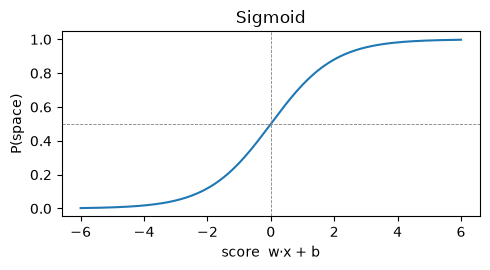

시그모이드(직접)  : [0.7711 0.4147]
predict_proba[:,1]: [0.7711 0.4147]


In [4]:
s = np.linspace(-6, 6, 200)
fig, ax = plt.subplots(figsize=(5, 2.8))
ax.plot(s, 1 / (1 + np.exp(-s)))
ax.axhline(0.5, color="gray", lw=0.6, ls="--")
ax.axvline(0, color="gray", lw=0.6, ls="--")
ax.set_xlabel("score  w·x + b")
ax.set_ylabel("P(space)")
ax.set_title("Sigmoid")
fig.tight_layout()
plt.show()

sigmoid = 1 / (1 + np.exp(-manual))
print("시그모이드(직접)  :", sigmoid.round(4))
print("predict_proba[:,1]:", mini_model.predict_proba(X_new)[:, 1].round(4))

### 여러 카테고리: 소프트맥스
카테고리가 $K$개면 카테고리마다 가중치 벡터 $w_k$와 절편 $b_k$가 있어 점수도 $K$개 나옵니다. **소프트맥스(softmax)**는 점수 $K$개를 합이 1인 확률 $K$개로 바꿉니다.

$$P(k \mid x) = \frac{e^{s_k}}{\sum_{j=1}^{K} e^{s_j}}, \qquad s_k = w_k \cdot x + b_k$$

점수가 가장 큰 카테고리가 확률도 가장 크므로, 예측은 점수의 `argmax`와 같습니다. 영어 데이터(5개 카테고리)로 확인합니다.

In [5]:
t0 = time.perf_counter()
res_en = run_classification(en, "en")
print(f"학습 시간 {time.perf_counter() - t0:.1f}초 | Test 정확도 {res_en.accuracy:.3f}")
print("coef_ shape:", res_en.model.coef_.shape, "= (카테고리 수, 어휘 수)")

scores = res_en.X_test @ res_en.model.coef_.T + res_en.model.intercept_     # (Test 문서 수, 5)
e = np.exp(scores - scores.max(axis=1, keepdims=True))                      # 큰 수 방지: 최댓값을 빼도 결과는 같다
softmax = e / e.sum(axis=1, keepdims=True)

print("소프트맥스(직접) == predict_proba :", np.allclose(softmax, res_en.proba))
print("argmax(점수) == predict          :",
      np.array_equal(np.array(res_en.labels)[scores.argmax(axis=1)], res_en.y_pred))
print("\n첫 Test 문서의 확률:", {lab: round(float(p), 3) for lab, p in zip(res_en.labels, res_en.proba[0])})

학습 시간 1.2초 | Test 정확도 0.900
coef_ shape: (5, 11488) = (카테고리 수, 어휘 수)
소프트맥스(직접) == predict_proba : True
argmax(점수) == predict          : True

첫 Test 문서의 확률: {'comp.graphics': 0.23, 'comp.windows.x': 0.494, 'rec.sport.baseball': 0.097, 'rec.sport.hockey': 0.07, 'sci.space': 0.108}


`predict_proba`는 **모델이 얼마나 확신하는지**를 보여 줍니다. 20장에서 "확신했는데 틀린 문서"를 찾을 때 씁니다.

## 18.3 선형 SVM과 비교

**선형 SVM**(`LinearSVC`)도 같은 $w \cdot x + b$ 점수를 씁니다. 차이는 가중치를 **고르는 기준**입니다.

| | 로지스틱 회귀 | 선형 SVM |
|---|---|---|
| 학습 목표 | 정답의 확률을 높인다 (모든 문서가 학습에 기여) | 카테고리 사이의 **여백(margin)**을 가장 넓게 한다 (경계 근처 문서가 주로 기여) |
| 확률 출력 | `predict_proba` 있음 | 없음 (점수만) |
| 이 과제에서 | 확신도를 오분류 분석에 쓸 수 있다 | 점수만으로 분류 |

여백 직관: 두 카테고리 점들 사이에 선을 그을 때, 양쪽 점에서 **가장 멀리 떨어진** 선을 고르면 새 점이 조금 흔들려도 잘 버틴다는 생각입니다.

In [6]:
from sklearn.svm import LinearSVC

rows = {}
for lang, corpus in [("en", en), ("ko", ko)]:
    train, test = split(corpus)
    vec = NumpyTfidf(min_df=MIN_DF[lang])
    X_tr, X_te = vec.fit_transform(train["tokens"].tolist()), vec.transform(test["tokens"].tolist())
    for name, model in [("LogisticRegression", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
                        ("LinearSVC", LinearSVC(random_state=RANDOM_STATE))]:
        pred = model.fit(X_tr, train["label"]).predict(X_te)
        rows[(lang, name)] = {"정확도": accuracy_score(test["label"], pred),
                              "macro F1": f1_score(test["label"], pred, average="macro")}
pd.DataFrame(rows).T.round(3)

정확도  macro F1
en LogisticRegression  0.900     0.900
   LinearSVC           0.897     0.897
ko LogisticRegression  0.770     0.770
   LinearSVC           0.759     0.757

두 모델의 성능은 비슷합니다. 이 과제에서는 **로지스틱 회귀**를 기본선으로 고릅니다. 성능 차이가 작고, `predict_proba`로 확신도를 볼 수 있어 오분류 분석(20장)에 유리하기 때문입니다.

## 18.4 규제 강도 `C`

가중치가 지나치게 커지면 학습 문서의 사소한 단어까지 외우게 됩니다(과적합). **규제(regularization)**는 큰 가중치에 벌점을 줘서 이를 막습니다. sklearn에서 `C`는 **규제의 역수**입니다.

| `C` | 규제 | 경향 |
|---|---|---|
| 작다 (0.01) | 강하다 | 가중치가 작게 눌림 → Train도 Test도 덜 맞춤 (과소적합) |
| 크다 (100) | 약하다 | Train을 거의 완벽하게 맞춤 → 과적합 위험 |

In [7]:
train, test = split(en)
vec = NumpyTfidf(min_df=MIN_DF["en"])
X_tr, X_te = vec.fit_transform(train["tokens"].tolist()), vec.transform(test["tokens"].tolist())
c_rows = []
for C in [0.01, 0.1, 1, 10, 100]:
    m = LogisticRegression(C=C, max_iter=2000, random_state=RANDOM_STATE).fit(X_tr, train["label"])
    c_rows.append({"C": C, "Train 정확도": m.score(X_tr, train["label"]), "Test 정확도": m.score(X_te, test["label"]),
                   "가중치 크기(최대 |w|)": np.abs(m.coef_).max()})
pd.DataFrame(c_rows).set_index("C").round(3)

,Train 정확도,Test 정확도,가중치 크기(최대 |w|)
C,,,
0.01,0.862,0.801,0.265
0.10,0.940,0.889,1.907
1.00,0.981,0.900,5.336
10.00,1.000,0.898,9.077
100.00,1.000,0.900,13.667


- `C`가 커질수록 가중치가 커지고 Train 정확도는 1.000에 다가갑니다.
- Test 정확도는 `C=1` 근처에서 이미 충분하고, 더 키워도 좋아지지 않습니다. Train과 Test의 차이만 벌어집니다.
- 이 과제는 기본값 `C=1.0`을 씁니다. `C`를 Test 점수를 보며 고르면 17장에서 말한 누수가 되므로, 제대로 고르려면 Train 안에서 다시 검증용 데이터를 떼어(교차 검증) 골라야 합니다. 기본선 실험에서는 기본값으로 충분합니다.

## 18.5 sklearn 사용법 정리

| 코드 | 하는 일 |
|---|---|
| `LogisticRegression(C=1.0, max_iter=2000, random_state=42)` | 모델 만들기 |
| `model.fit(X_train, y_train)` | 학습 |
| `model.predict(X)` | 예측 레이블 |
| `model.predict_proba(X)` | 카테고리별 확률, 열 순서는 `model.classes_` |
| `model.decision_function(X)` | 확률 전 점수 $w \cdot x + b$ |
| `model.coef_`, `model.intercept_` | 가중치 `(K, V)`, 절편 `(K,)` |
| `model.n_iter_` | 학습에 걸린 반복 횟수 |

### `max_iter`와 수렴 경고
로지스틱 회귀는 가중치를 조금씩 고쳐 가며 최적값을 찾습니다(반복 최적화). 반복 횟수가 모자라면 끝까지 가지 못하고 `ConvergenceWarning`을 냅니다. 어휘가 수만 개인 텍스트 데이터는 기본값(100)으로 부족할 때가 있어 `max_iter=2000`을 줍니다.

In [8]:
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    short = LogisticRegression(max_iter=5, random_state=RANDOM_STATE).fit(X_tr, train["label"])
print("max_iter=5   :", [w.category.__name__ for w in caught][:1], f"| Test 정확도 {short.score(X_te, test['label']):.3f}")

full = LogisticRegression(max_iter=2000, random_state=RANDOM_STATE).fit(X_tr, train["label"])
print("max_iter=2000: 실제 반복", full.n_iter_, f"| Test 정확도 {full.score(X_te, test['label']):.3f}")

max_iter=5   : ['ConvergenceWarning'] | Test 정확도 0.873


max_iter=2000: 실제 반복 [45] | Test 정확도 0.900


## 18.6 고차원 희소 특성에 선형 모델이 잘 맞는 이유

In [9]:
nonzero = (X_tr > 0).sum(axis=1)
print(f"Train 문서 수 {X_tr.shape[0]:,} / 특성(어휘) 수 {X_tr.shape[1]:,}")
print(f"문서 하나에서 0이 아닌 특성: 평균 {nonzero.mean():.0f}개 ({nonzero.mean() / X_tr.shape[1]:.2%})")
svm_train_acc = LinearSVC(random_state=RANDOM_STATE).fit(X_tr, train["label"]).score(X_tr, train["label"])
print(f"LinearSVC의 Train 정확도: {svm_train_acc:.4f} → 직선(초평면)만으로 Train 문서를 거의 다 나눌 수 있다")

Train 문서 수 3,716 / 특성(어휘) 수 11,488
문서 하나에서 0이 아닌 특성: 평균 55개 (0.48%)
LinearSVC의 Train 정확도: 0.9997 → 직선(초평면)만으로 Train 문서를 거의 다 나눌 수 있다


1. **특성이 문서보다 많습니다.** 차원이 높으면 점들을 직선(고차원에서는 초평면)으로 나누기 쉬워집니다. 위에서 선형 SVM이 Train 문서를 거의 완벽하게 나눴습니다. 복잡한 곡선 경계가 필요 없습니다.
2. **문서마다 0이 아닌 특성이 아주 적습니다.** 점수 계산 $w \cdot x$가 몇십 개 단어의 가중치 합이라 빠르고, 단어 하나하나의 기여를 그대로 읽을 수 있습니다.
3. **해석이 됩니다.** "`hockey`가 나오면 하키 쪽 점수가 오른다"처럼 가중치를 사람이 읽을 수 있어, 오분류 원인을 단어 단위로 분석할 수 있습니다(20장). 과제가 BoW의 한계를 분석하라고 하는 만큼 이 해석 가능성이 중요합니다.

## 18.7 클래스별 대표 단어

카테고리마다 가중치가 가장 큰 단어를 보면 모델이 무엇을 배웠는지 알 수 있습니다.

In [10]:
def top_words(res, k=10):
    return pd.DataFrame({lab: res.vec.terms_[np.argsort(-res.model.coef_[i])[:k]]
                         for i, lab in enumerate(res.labels)})


print("영어: 카테고리별 가중치 상위 10개 단어")
top_words(res_en)

영어: 카테고리별 가중치 상위 10개 단어


,comp.graphics,comp.windows.x,rec.sport.baseball,rec.sport.hockey,sci.space
0,graphics,window,baseball,hockey,space
1,computer,server,year,game,orbit
2,image,motif,cubs,nhl,nasa
3,files,xterm,hit,team,shuttle
4,format,widget,ball,playoff,launch
5,file,windows,pitcher,playoffs,earth
6,pov,use,jewish,season,moon
7,images,mit,braves,leafs,spacecraft
8,bit,sun,sox,espn,solar
9,tiff,application,pitching,cup,sky


In [11]:
res_ko = run_classification(ko, "ko")
print(f"한국어 Test 정확도 {res_ko.accuracy:.3f}. 카테고리별 가중치 상위 10개 단어")
top_words(res_ko)

한국어 Test 정확도 0.770. 카테고리별 가중치 상위 10개 단어


,IT과학,경제,사회,생활문화,세계,스포츠,정치
0,개발,투자,방통위,신간,美,감독,北
1,g,영업,kbs,축제,트럼프,류현진,대통령
2,출시,코스피,mbc,여행,이란,월드컵,남북
3,ai,증권,회장,공연,中,프로농구,朴
4,kt,금융,노조,베스트셀러,터키,경기,靑
5,아이폰,대출,원장,소설,日,리그,김정은
6,스마트폰,익,기자,날씨,이스라엘,축구,국회
7,lg,실적,사장,도,시위,손흥민,與
8,s,코스닥,언론,개막,시리아,mlb,정부
9,skt,특징,방송,작가,미국,연승,민주


대부분 그 주제를 대표하는 단어들입니다. 눈여겨볼 점:
- 영어 `comp.graphics`와 `comp.windows.x`의 상위 단어는 각자 뚜렷하지만, 두 게시판은 `file`, `program`, `display` 같은 중간 어휘를 많이 공유합니다. 19장에서 이 둘이 가장 많이 헷갈리는 것을 확인합니다.
- 한국어 상위 단어에는 `北`, `美` 같은 한자(8장에서 남기기로 한 것)와 `kt`, `lg` 같은 영문 기업명이 보입니다. 전처리 선택이 모델에 그대로 반영됩니다.
- 한국어 IT과학의 `g`(`5G`에서 숫자가 떨어진 조각), `s`(`갤럭시S8`의 조각)처럼 전처리가 만든 조각도 상위에 올라옵니다. 이런 토큰은 전처리를 다시 점검할 신호이고, 20장 오분류 사례에서도 원인으로 등장합니다.
- 영어 baseball의 `jewish`처럼 특정 토론 스레드에서 많이 나온 단어도 보입니다. 모델은 주제의 본질이 아니라 **이 데이터에서 자주 함께 나온 단어**를 배운다는 뜻입니다.

## 📝 리포트용 정리: 모델 선택

| 항목 | 내용 |
|---|---|
| 모델 | `LogisticRegression(C=1.0, max_iter=2000, random_state=42)`, 다중 클래스는 소프트맥스 |
| 특성 | 직접 구현한 TF-IDF (raw TF, smooth IDF, L2 정규화, 영어 `min_df=3`, 한국어 `min_df=2`, Train으로만 fit) |
| 선택 이유 | LinearSVC와 성능이 비슷하고(18.3), `predict_proba`로 확신도를 볼 수 있으며, 단어별 가중치로 예측을 설명할 수 있다 |
| `C` | 기본값 1.0. `C`를 키우면 Train만 1.000에 가까워지고 Test는 나아지지 않음(18.4) |

## ✍️ 실습: 예측을 손으로 재현하기

한국어 결과 `res_ko`로 다음을 하세요.
1. `X_test @ coef_.T + intercept_`로 점수 행렬을 만들고, 행마다 `argmax`로 예측 레이블을 구해 `res_ko.y_pred`와 모두 같은지 확인
2. Test 첫 문서에서 **예측 카테고리의 점수**에 가장 크게 기여한 단어 5개를 `coef_[예측 클래스] * x`로 구해 출력

In [12]:
# 여기에 작성하세요

**정답**

In [13]:
scores_ko = res_ko.X_test @ res_ko.model.coef_.T + res_ko.model.intercept_
manual_pred = np.array(res_ko.labels)[scores_ko.argmax(axis=1)]
print("직접 계산한 예측 == predict:", np.array_equal(manual_pred, res_ko.y_pred))

r = 0
c = res_ko.labels.index(res_ko.y_pred[r])
contrib = res_ko.model.coef_[c] * res_ko.X_test[r]          # 단어별 기여도
top = np.argsort(-contrib)[:5]
print(f"\n문서: {res_ko.test.loc[r, 'text']}")
print(f"예측: {res_ko.y_pred[r]} / 실제: {res_ko.test.loc[r, 'label']}")
print("기여 단어:", [(res_ko.vec.terms_[j], round(float(contrib[j]), 3)) for j in top if contrib[j] > 0])

직접 계산한 예측 == predict: True

문서: 출시 하루 앞둔 삼성 갤럭시폴드 써보니…결함논란 개선 뚜렷
예측: IT과학 / 실제: IT과학
기여 단어: [('출시', 0.753), ('갤럭시', 0.573), ('보다', 0.202), ('삼성', 0.189), ('써다', 0.15)]


단어별 기여도를 모두 더하고 절편을 더하면 그 카테고리의 점수가 됩니다. 20장 오분류 분석은 이 계산을 틀린 문서에 적용하는 것입니다.

## 🧐 퀴즈

**Q1.** 문서 벡터 $x$의 0이 아닌 칸이 `space`(0.6), `launch`(0.8)뿐이고, sci.space 클래스의 가중치가 `space`=2.0, `launch`=1.5, 절편이 −0.5라면 sci.space 점수는?
<details><summary>▶ 정답 보기</summary>

$0.6 \times 2.0 + 0.8 \times 1.5 - 0.5 = 1.2 + 1.2 - 0.5 = 1.9$. 0인 칸은 가중치가 무엇이든 점수에 영향을 주지 않습니다.
</details>

**Q2.** 소프트맥스에서 모든 점수에 같은 수를 더하거나 빼도 확률이 바뀌지 않는 이유는? 코드에서 이 성질을 어디에 썼나요?
<details><summary>▶ 정답 보기</summary>

$e^{s_k + c} = e^c e^{s_k}$이므로 분자와 분모에 같은 $e^c$가 곱해져 약분됩니다. 코드에서 `scores - scores.max(...)`로 최댓값을 빼서 `exp`가 너무 큰 수가 되는 것(오버플로)을 막았습니다.
</details>

**Q3.** `C`를 100으로 올렸더니 Train 정확도가 1.000이 됐습니다. 좋은 일인가요?
<details><summary>▶ 정답 보기</summary>

아닙니다. 규제가 약해져 학습 문서를 외운 것일 수 있습니다. Test 정확도가 오르지 않았다면 일반화는 나아지지 않고 과적합 위험만 커진 것입니다.
</details>

**Q4.** 이 과제에서 LinearSVC 대신 로지스틱 회귀를 기본선으로 고른 이유 두 가지는?
<details><summary>▶ 정답 보기</summary>

① 성능이 비슷하다. ② `predict_proba`로 확신도를 얻을 수 있어 "확신했는데 틀린" 오분류를 찾고 분석하기 좋다. (단어별 가중치로 예측을 설명할 수 있는 것은 두 모델 모두 같습니다.)
</details>

**Q5.** `ConvergenceWarning`이 나왔을 때 첫 번째로 해 볼 일은?
<details><summary>▶ 정답 보기</summary>

`max_iter`를 늘려 최적화가 끝까지 수렴하게 합니다. 경고를 무시하면 덜 학습된 가중치로 평가하게 됩니다.
</details>

## ✅ 체크포인트
- [ ] $w \cdot x + b$로 점수를 직접 계산해 `decision_function`과 맞출 수 있다.
- [ ] 소프트맥스를 직접 계산해 `predict_proba`와 맞출 수 있다.
- [ ] 로지스틱 회귀와 LinearSVC의 차이와 이 과제의 선택 이유를 말할 수 있다.
- [ ] `C`를 바꿨을 때 Train/Test 점수의 변화를 해석할 수 있다.
- [ ] 카테고리별 대표 단어를 뽑아 해석할 수 있다.

## 🔗 과제 연결과 다음 장
- 모델 설정과 선택 이유는 README의 분류 실험 부분에, 대표 단어 표는 분석 근거로 씁니다.
- **19장. 평가 지표와 혼동 행렬**에서 정확도만으로는 보이지 않는 카테고리별 성능을 측정하고 혼동 행렬을 그립니다.